# SmolVLM backbone, step by step 🐭
### How a 256M-parameter VLM sees: image splitting, a SigLIP encoder, pixel shuffle and a small Llama

**Model:** SmolVLM (Hugging Face, 2024–2025): SmolVLM-256M, -500M and -2.2B, plus the SmolVLM2 video
variants. It descends from Idefics3. The vision side is a SigLIP encoder; the language side is SmolLM2,
a Llama-architecture decoder.

Qwen3-VL (see the companion notebook) spends compute on a large ViT and rich position encodings.
SmolVLM is designed for **on-device** budgets. Its backbone is deliberately simple, and almost every
choice serves to **spend as few LLM tokens per pixel as possible**:

| Step | Question it answers | Animation |
|---|---|---|
| 0 | What are the parts and the tensor shapes? | pipeline |
| 1 | How is a large image fed to a small encoder? (resize + split into tiles + global view) | tiling |
| 2 | How does the LLM know where each tile was? (position tags in the prompt) | token stream |
| 3 | How does the encoder embed patches and positions, even for padded tiles? (NaViT-style buckets) | |
| 4 | The SigLIP encoder layer | |
| 5 | How do 16 patches become 1 token? (pixel shuffle) | pixel shuffle |
| 6 | Projection and merging image tokens into the prompt | |
| 7 | The SmolLM2 (Llama) decoder, end to end | |
| 8 | Token budget: SmolVLM vs Qwen3-VL | |

Every step is **re-implemented from scratch in plain PyTorch and checked numerically against
🤗 `transformers`** (`SmolVLMModel`) on a tiny random-weight model with the real architecture. An
optional cell at the end repeats the checks on `HuggingFaceTB/SmolVLM-256M-Instruct`.

> 🧩 **Reference code:** `transformers/models/smolvlm/{modeling,image_processing,processing}_smolvlm.py`.
> 🎞️ **Animations:** `hale_vlm.visualization.backbone_films`, rendered into `assets/backbone_films/`.

## Setup

The cell below makes the repo's `src/` importable (the notebook lives in `notebooks/backbones/vlm/`),
plus a sibling `HaleBlocks/src` checkout when present (as the repo's tests do), quietens the library
loggers and fixes the seeds.

In [1]:
import math, re, sys, warnings
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "hale_vlm").is_dir())
for src in (ROOT.parent / "HaleBlocks" / "src", ROOT / "src"):   # sibling HaleBlocks checkout, then this repo
    if src.is_dir():
        sys.path.insert(0, str(src))
FILMS = ROOT / "assets" / "backbone_films"

from loguru import logger
logger.remove(); logger.add(sys.stderr, level="WARNING")
warnings.filterwarnings("ignore", category=FutureWarning)

import transformers
from transformers import SmolVLMConfig, SmolVLMModel, SmolVLMImageProcessor
from hale_vlm.visualization.backbone_films import FilmCatalog, MergeMappingProbe, SyntheticScene

torch.manual_seed(0); np.random.seed(0)
torch.set_printoptions(precision=4, sci_mode=False, linewidth=110)
plt.rcParams.update({"figure.facecolor": "#0f1117", "axes.facecolor": "#0f1117", "axes.edgecolor": "#8a91a3",
                     "axes.labelcolor": "#e8eaf0", "text.color": "#e8eaf0", "xtick.color": "#8a91a3",
                     "ytick.color": "#8a91a3", "axes.titleweight": "bold"})

def check(name, ours, ref, atol=1e-5):
    # Compare our from-scratch tensor with the transformers reference and print the max error.
    ours, ref = torch.as_tensor(ours).float(), torch.as_tensor(ref).float()
    assert ours.shape == ref.shape, f"{name}: shape {tuple(ours.shape)} vs {tuple(ref.shape)}"
    err = (ours - ref).abs().max().item() if ours.numel() else 0.0
    status = "✅" if err <= atol else "❌"
    print(f"{status} {name:<44} shape {str(tuple(ours.shape)):<20} max|Δ| = {err:.2e}")
    assert err <= atol, f"{name} differs from transformers by {err}"

print("torch", torch.__version__, "| transformers", transformers.__version__)

/Users/naveenkumarbasaanitha/Music/Hale-VLM/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.13.0 | transformers 5.16.1


## Step 0: the big picture

```mermaid
flowchart LR
  IMG["image (H, W)"]:::io --> RS["resize: longest edge ≤ 4·tile,<br/>sides rounded up to tile"]:::vis
  RS --> SP["split: rows × cols tiles<br/>+ 1 global view"]:::vis
  SP --> ENC["SigLIP encoder<br/>(per tile, patch 16)"]:::vis
  ENC --> PS["pixel shuffle r = 4<br/>16 patches → 1 token"]:::tok
  PS --> PR["Linear (no bias)<br/>→ LLM width"]:::tok
  TXT["prompt with &lt;row_r_col_c&gt; tags<br/>and &lt;image&gt; × 64 per tile"]:::io --> EMB["token embedding"]:::txt
  PR -- "fill &lt;image&gt; slots" --> EMB
  EMB --> LLM["SmolLM2 decoder<br/>(Llama: 1-D RoPE, GQA, SwiGLU)"]:::txt --> OUT["hidden states"]:::io
  classDef io fill:#2b2410,stroke:#d48806,color:#fff
  classDef vis fill:#10223f,stroke:#4c8dff,color:#fff
  classDef tok fill:#3a2e0a,stroke:#f5b829,color:#fff
  classDef txt fill:#0f2e22,stroke:#3ecf8e,color:#fff
```

The animation follows a 1100×1600 photo through SmolVLM-256M: 3×4 tiles + 1 global view = 13 encoder
images, and 64 tokens each.

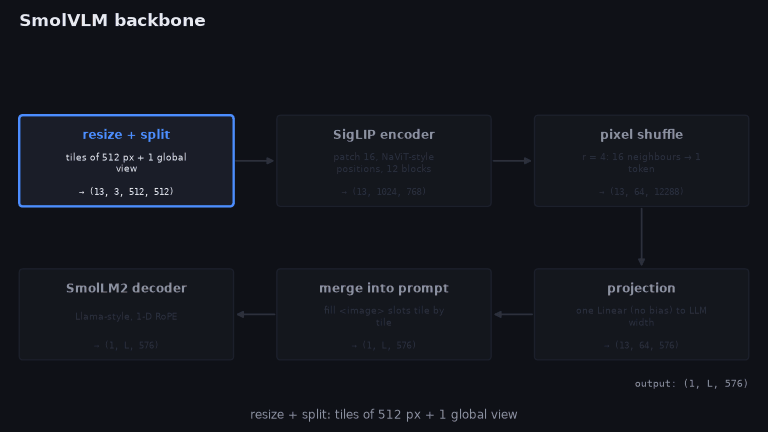

In [2]:
display(FilmCatalog.smolvlm_pipeline().show(FILMS / "smolvlm_pipeline.gif"))

### The released family vs the toy model in this notebook

| model | vision encoder | tile (px) | patch | patches / tile | shuffle r | **tokens / tile** | language model |
|---|---|---|---|---|---|---|---|
| SmolVLM-256M | SigLIP base (93M) | 512 | 16 | 32×32 = 1024 | 4 | **64** | SmolLM2-135M |
| SmolVLM-500M | SigLIP base (93M) | 512 | 16 | 1024 | 4 | **64** | SmolLM2-360M |
| SmolVLM-2.2B | SigLIP so400m | 384 | 14 | 27×27 = 729 | 3 | **81** | SmolLM2-1.7B |

We count the two encoder sizes on the `meta` device (no memory is used), then build a tiny model with
the **same structure**: 128-px tiles, patch 8 (16×16 = 256 patches) and r = 4, giving 16 tokens per tile.

In [3]:
from transformers import SmolVLMVisionConfig
from transformers.models.smolvlm.modeling_smolvlm import SmolVLMVisionTransformer

encoders = {
    "SigLIP base / 512 / p16 (256M, 500M)": SmolVLMVisionConfig(hidden_size=768, intermediate_size=3072,
        num_hidden_layers=12, num_attention_heads=12, image_size=512, patch_size=16),
    "SigLIP so400m / 384 / p14 (2.2B)": SmolVLMVisionConfig(hidden_size=1152, intermediate_size=4304,
        num_hidden_layers=27, num_attention_heads=16, image_size=384, patch_size=14),
}
for name, vc in encoders.items():
    with torch.device("meta"):
        enc = SmolVLMVisionTransformer(vc)
    n = sum(p.numel() for p in enc.parameters())
    side = vc.image_size // vc.patch_size
    print(f"{name:<38} {n / 1e6:6.1f} M params | {side}×{side} = {side * side} patches per tile, width {vc.hidden_size}")

SigLIP base / 512 / p16 (256M, 500M)     86.4 M params | 32×32 = 1024 patches per tile, width 768
SigLIP so400m / 384 / p14 (2.2B)        413.0 M params | 27×27 = 729 patches per tile, width 1152


In [4]:
cfg = SmolVLMConfig(
    vision_config=dict(hidden_size=64, intermediate_size=128, num_hidden_layers=3, num_attention_heads=4,
                       image_size=128, patch_size=8),
    text_config=dict(model_type="llama", vocab_size=300, hidden_size=96, intermediate_size=192,
                     num_hidden_layers=3, num_attention_heads=4, num_key_value_heads=2,
                     rope_theta=100000.0, rms_norm_eps=1e-5, pad_token_id=0),
    scale_factor=4, image_token_id=290, pad_token_id=0)

torch.manual_seed(0)
model = SmolVLMModel(cfg).eval()
with torch.no_grad():                      # move every weight off its init value so checks are meaningful
    for p in model.parameters():
        p.add_(0.05 * torch.randn_like(p))
VIS, CONN, LM = model.vision_model, model.connector, model.text_model
vcfg, tcfg = cfg.vision_config, cfg.text_config
TILE, PATCH, R = vcfg.image_size, vcfg.patch_size, cfg.scale_factor
print(f"toy model: {sum(p.numel() for p in model.parameters()) / 1e3:.0f} k params | tile {TILE}px, "
      f"patch {PATCH} → {(TILE // PATCH) ** 2} patches → shuffle r={R} → {model.image_seq_len} tokens per tile | "
      f"LLM width {tcfg.hidden_size}, {tcfg.num_attention_heads} q / {tcfg.num_key_value_heads} kv heads")

toy model: 506 k params | tile 128px, patch 8 → 256 patches → shuffle r=4 → 16 tokens per tile | LLM width 96, 4 q / 2 kv heads


## Step 1: resize, then split into tiles + one global view

A small encoder sees one fixed-size square (512 px for SigLIP base). To read a large photo or a page of
small text, SmolVLM (like Idefics3) does **image splitting**:

1. rescale so the longest edge is `size.longest_edge` (4 tiles = 2048 px for the 256M model),
   keeping the aspect ratio;
2. round **each side up** to a multiple of the tile size (`max_image_size.longest_edge`);
3. cut that into `rows × cols` tiles, and append the **whole image squashed to one tile** as a global
   view, so the model keeps the layout.

Compute grows with resolution only through the **number of tiles**. The encoder itself never changes.
Our toy uses 128-px tiles and a 512-px longest edge, the same ratio as the 256M model.

In [5]:
def plan_tiles(height, width, longest_edge, tile):
    # (resized_h, resized_w, rows, cols) the way SmolVLMImageProcessor sizes an image before splitting.
    aspect = width / height
    if width >= height:                                          # 1. longest edge → longest_edge
        width = longest_edge; height = int(width / aspect); height += height % 2
    else:
        height = longest_edge; width = int(height * aspect); width += width % 2
    resized_h = math.ceil(height / tile) * tile                  # 2. round each side up to the tile
    resized_w = math.ceil(width / tile) * tile
    return resized_h, resized_w, resized_h // tile, resized_w // tile

processor = SmolVLMImageProcessor(size={"longest_edge": 4 * TILE}, max_image_size={"longest_edge": TILE},
                                  do_image_splitting=True, image_mean=[0.5] * 3, image_std=[0.5] * 3)
for h, w in [(200, 300), (300, 200), (1100, 1600), (90, 700), (512, 512)]:
    ours = plan_tiles(h, w, 4 * TILE, TILE)
    n_images, rows, cols = processor.get_number_of_image_patches(h, w, {})
    assert (rows, cols) == ours[2:] and n_images == rows * cols + 1
    print(f"{h:>5}×{w:<5} → {ours[0]}×{ours[1]} → {rows}×{cols} tiles + 1 global = {n_images} encoder images "
          f"= {n_images * model.image_seq_len} LLM tokens   ✅ same as transformers")

  200×300   → 384×512 → 3×4 tiles + 1 global = 13 encoder images = 208 LLM tokens   ✅ same as transformers
  300×200   → 512×384 → 4×3 tiles + 1 global = 13 encoder images = 208 LLM tokens   ✅ same as transformers
 1100×1600  → 384×512 → 3×4 tiles + 1 global = 13 encoder images = 208 LLM tokens   ✅ same as transformers
   90×700   → 128×512 → 1×4 tiles + 1 global = 5 encoder images = 80 LLM tokens   ✅ same as transformers
  512×512   → 512×512 → 4×4 tiles + 1 global = 17 encoder images = 272 LLM tokens   ✅ same as transformers


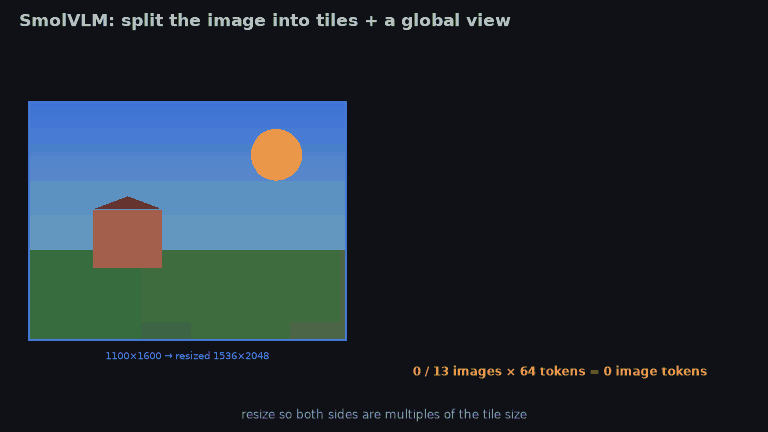

In [6]:
display(FilmCatalog.smolvlm_image_tiling().show(FILMS / "smolvlm_image_tiling.gif"))

Now the split itself. The test image is 384×512, which is already the planned size (3×4 tiles of 128),
so the resize steps are the identity. Tiles are cut with two `unfold`s, row by row, and must match the
processor's tensors exactly. The global view is a Lanczos downsample by the processor; we only show it.

✅ tiles (row-major)                            shape (12, 3, 128, 128)    max|Δ| = 5.91e-08
processor output: (1, 13, 3, 128, 128) = rows 3 × cols 4 + 1 global view


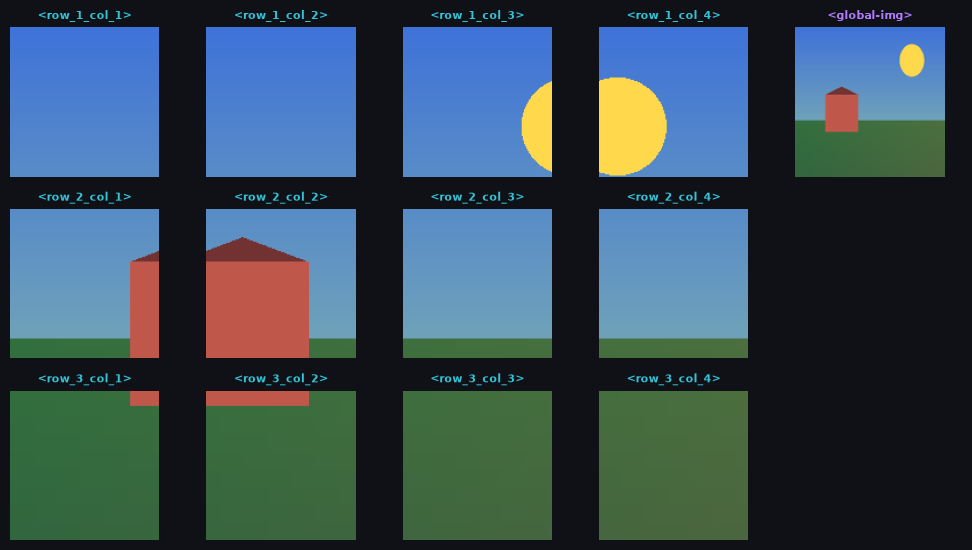

In [7]:
scene = (SyntheticScene.render(384, 512) * 255).astype(np.uint8)
batch = processor(images=[[scene]], return_tensors="pt", return_row_col_info=True)
rows, cols = batch["rows"][0][0], batch["cols"][0][0]

def split_tiles(image_uint8, tile):
    # (H, W, 3) uint8 with H, W multiples of `tile` -> (rows·cols, 3, tile, tile) normalised tiles.
    x = torch.from_numpy(image_uint8).permute(2, 0, 1).float() / 255.0
    x = (x - 0.5) / 0.5
    tiles = x.unfold(1, tile, tile).unfold(2, tile, tile)        # (3, rows, cols, tile, tile)
    return tiles.permute(1, 2, 0, 3, 4).reshape(-1, 3, tile, tile)

ours_tiles = split_tiles(scene, TILE)
check("tiles (row-major)", ours_tiles, batch["pixel_values"][0, :-1], atol=1e-5)
pixel_values = batch["pixel_values"][0]                      # (rows·cols + 1, 3, 128, 128): tiles + global
print(f"processor output: {tuple(batch['pixel_values'].shape)} = rows {rows} × cols {cols} + 1 global view")

fig, axes = plt.subplots(rows, cols + 1, figsize=(10, 5.6))
for i in range(rows):
    for j in range(cols + 1):
        ax = axes[i, j]; ax.axis("off")
        k = i * cols + j if j < cols else (rows * cols if i == 0 else None)
        if k is None: continue
        ax.imshow((pixel_values[k].permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1))
        ax.set_title(f"<row_{i + 1}_col_{j + 1}>" if j < cols else "<global-img>", fontsize=8,
                     color="#33c3d6" if j < cols else "#b07cff")
plt.tight_layout(); plt.show()

## Step 2: the prompt, where position tags tell the LLM where each tile was

The tiles reach the LLM as one flat run of tokens, so their 2-D layout must be spelled out. The processor
replaces each `<image>` in the text with:

```
<fake_token_around_image><row_1_col_1><image>×64 <fake_token_around_image><row_1_col_2><image>×64 … \n
…
\n<fake_token_around_image><global-img><image>×64<fake_token_around_image>
```

`<row_r_col_c>` and `<global-img>` are **learned special tokens**. The SmolVLM paper reports that, at
this scale, learned positional tokens work clearly better than spelling the position out as plain text.
`<fake_token_around_image>` marks the boundaries between images. The LLM itself uses ordinary 1-D RoPE;
all 2-D information comes from these tags and from the order of the tiles.

In [8]:
def expand_image_prompt(seq_len, rows, cols, fake="<fake_token_around_image>", image="<image>",
                        global_img="<global-img>"):
    # The text that replaces one <image> in the prompt.
    if rows == 0 and cols == 0:                                           # small image: global view only
        return f"{fake}{global_img}{image * seq_len}{fake}"
    text = ""
    for r in range(rows):
        for c in range(cols):
            text += f"{fake}<row_{r + 1}_col_{c + 1}>{image * seq_len}"
        text += "\n"
    return text + f"\n{fake}{global_img}{image * seq_len}{fake}"

from transformers.models.smolvlm.processing_smolvlm import _prompt_split_image, _prompt_single_image
assert expand_image_prompt(16, rows, cols) == _prompt_split_image(16, rows, cols, "<fake_token_around_image>",
                                                                   "<image>", "<global-img>")
assert expand_image_prompt(16, 0, 0) == _prompt_single_image(16, "<fake_token_around_image>", "<image>",
                                                             "<global-img>")
print("✅ prompt expansion identical to transformers (split and single-image cases)")
print(re.sub(r"(<image>)+", lambda m: f"<image>×{len(m.group(0)) // 7}", expand_image_prompt(16, rows, cols)))

✅ prompt expansion identical to transformers (split and single-image cases)
<fake_token_around_image><row_1_col_1><image>×16<fake_token_around_image><row_1_col_2><image>×16<fake_token_around_image><row_1_col_3><image>×16<fake_token_around_image><row_1_col_4><image>×16
<fake_token_around_image><row_2_col_1><image>×16<fake_token_around_image><row_2_col_2><image>×16<fake_token_around_image><row_2_col_3><image>×16<fake_token_around_image><row_2_col_4><image>×16
<fake_token_around_image><row_3_col_1><image>×16<fake_token_around_image><row_3_col_2><image>×16<fake_token_around_image><row_3_col_3><image>×16<fake_token_around_image><row_3_col_4><image>×16

<fake_token_around_image><global-img><image>×16<fake_token_around_image>


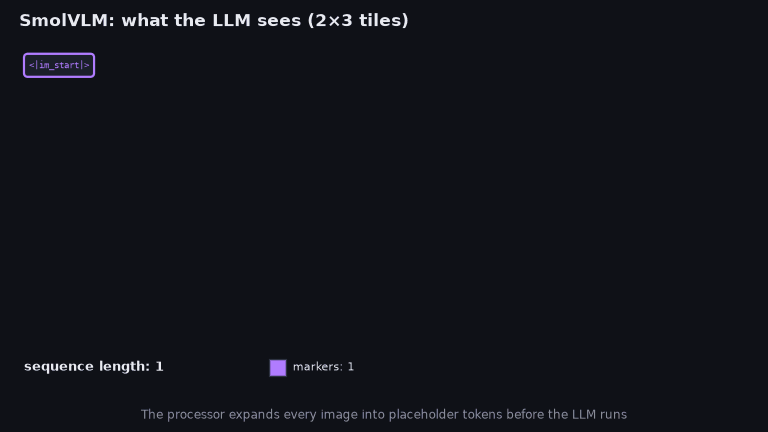

In [9]:
display(FilmCatalog.smolvlm_token_stream().show(FILMS / "smolvlm_token_stream.gif"))

We tokenise that prompt with a toy vocabulary: every special token gets its own id, and words get small
ids. The result is the `input_ids` used in the rest of the notebook.

In [10]:
special = {"<fake_token_around_image>": 280, "<global-img>": 281, "<image>": cfg.image_token_id,
           **{f"<row_{r}_col_{c}>": 250 + 10 * r + c for r in range(1, 5) for c in range(1, 5)}}
prompt = "User:" + expand_image_prompt(model.image_seq_len, rows, cols) + "Describe the scene."
pieces = re.findall(r"<[^>]+>|\w+|[^\w\s]|\n", prompt)
ids = [special[p] if p in special else 10 + sum(map(ord, p)) % 200 for p in pieces]
input_ids = torch.tensor([ids])
image_mask = input_ids == cfg.image_token_id
print(f"sequence length {input_ids.shape[1]}: {image_mask.sum().item()} image slots "
      f"({pixel_values.shape[0]} images × {model.image_seq_len}), {input_ids.shape[1] - image_mask.sum().item()} other tokens")

sequence length 245: 208 image slots (13 images × 16), 37 other tokens


## Step 3: patch embedding and NaViT-style position buckets

SigLIP embeds each tile with a `Conv2d(kernel = stride = patch)` and adds a **learned** position
embedding: a table of `(tile/patch)²` entries (16×16 in the toy, 32×32 in the 256M model).

Tiles at the right and bottom edges of an image, and batches mixing images of different sizes, can be
**padded**. SmolVLM inherits Idefics3's patch-n'-pack trick from NaViT (Dehghani et al., 2023). For a
tile whose *valid* region is $n_h \times n_w$ patches, patch $(i, j)$ gets the fractional coordinate
$(i/n_h,\ j/n_w)$, which is **bucketed** onto the full position grid. A small or oddly shaped valid region
is therefore *stretched over the whole table* instead of using only its top-left corner. Padded patches
keep position 0 and are masked out of attention.

Below we re-implement the embedding and check it on (a) full tiles and (b) a tile whose valid region is only
80×104 px (10×13 patches).

✅ embeddings, full tiles                       shape (13, 256, 64)        max|Δ| = 0.00e+00
✅ embeddings, padded tile (10×13 valid patches) shape (1, 256, 64)         max|Δ| = 0.00e+00


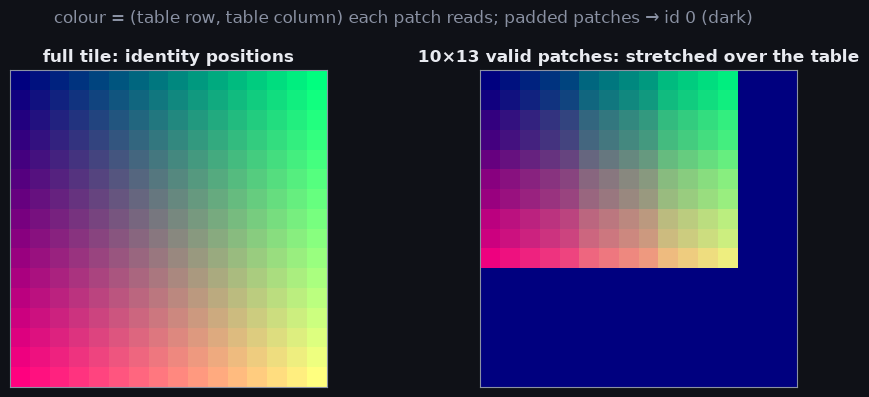

In [11]:
def patch_mask_from_pixels(pixel_mask, patch):
    # (N, H, W) pixel validity -> (N, H/patch, W/patch): a patch is valid if any of its pixels is.
    sub = pixel_mask.unfold(1, patch, patch).unfold(2, patch, patch)
    return sub.sum(dim=(-1, -2)) > 0

def vision_embed(pixel_values, patch_mask):
    emb = VIS.embeddings
    side = TILE // PATCH
    x = F.conv2d(pixel_values, emb.patch_embedding.weight, emb.patch_embedding.bias, stride=PATCH)
    x = x.flatten(2).transpose(1, 2)                                     # (N, side², C)
    boundaries = torch.arange(1 / side, 1.0, 1 / side)
    pos_ids = torch.zeros(x.shape[0], side * side, dtype=torch.long)
    for n, m in enumerate(patch_mask):
        nh, nw = m[:, 0].sum().item(), m[0, :].sum().item()              # valid patches per column / row
        fh = (torch.arange(side) / nh).clamp(max=1 - 1e-6)               # fractional coordinates
        fw = (torch.arange(side) / nw).clamp(max=1 - 1e-6)
        bh = torch.bucketize(fh, boundaries, right=True)                 # → bucket on the full grid
        bw = torch.bucketize(fw, boundaries, right=True)
        ids = (bh[:, None] * side + bw[None, :]).flatten()
        pos_ids[n, m.flatten()] = ids[m.flatten()]                       # padded patches keep id 0
    return x + emb.position_embedding(pos_ids), pos_ids

full_mask = torch.ones(pixel_values.shape[0], TILE // PATCH, TILE // PATCH, dtype=torch.bool)
pixel_mask = torch.zeros(1, TILE, TILE, dtype=torch.long); pixel_mask[:, :80, :104] = 1
partial_mask = patch_mask_from_pixels(pixel_mask, PATCH)
with torch.no_grad():
    ours_full, ids_full = vision_embed(pixel_values, full_mask)
    check("embeddings, full tiles", ours_full, VIS.embeddings(pixel_values, full_mask))
    ours_part, ids_part = vision_embed(pixel_values[:1], partial_mask)
    check("embeddings, padded tile (10×13 valid patches)", ours_part, VIS.embeddings(pixel_values[:1], partial_mask))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
side = TILE // PATCH
for ax, ids_, title in [(axes[0], ids_full[0], "full tile: identity positions"),
                        (axes[1], ids_part[0], "10×13 valid patches: stretched over the table")]:
    grid = ids_.view(side, side).float()
    rows_ids, cols_ids = grid // side, grid % side
    ax.imshow(np.dstack([rows_ids / (side - 1), cols_ids / (side - 1), 0.5 * np.ones((side, side))]))
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("colour = (table row, table column) each patch reads; padded patches → id 0 (dark)", color="#8a91a3")
plt.tight_layout(); plt.show()

## Step 4: the SigLIP encoder layer

A standard pre-LayerNorm ViT block: `x + Attn(LN(x))`, then `x + MLP(LN(x))`. It has separate `q/k/v`
projections with biases, **bidirectional** attention in which padded patches are masked out as keys,
and a `gelu(tanh)` MLP. There is no RoPE: position information came only from the learned table in
step 3. A final `post_layernorm` closes the encoder. Each tile is encoded **independently**; tiles never
attend to each other inside the encoder.

In [12]:
def encoder_layer(layer, x, key_mask):
    N, L, C = x.shape
    H = vcfg.num_attention_heads
    a = layer.self_attn
    h = F.layer_norm(x, (C,), layer.layer_norm1.weight, layer.layer_norm1.bias, eps=vcfg.layer_norm_eps)
    q, k, v = (proj(h).view(N, L, H, -1).transpose(1, 2) for proj in (a.q_proj, a.k_proj, a.v_proj))
    scores = q @ k.transpose(-1, -2) / math.sqrt(q.shape[-1])
    scores = scores.masked_fill(~key_mask[:, None, None, :], float("-inf"))   # ignore padded patches
    x = x + a.out_proj((scores.softmax(-1) @ v).transpose(1, 2).reshape(N, L, C))
    h = F.layer_norm(x, (C,), layer.layer_norm2.weight, layer.layer_norm2.bias, eps=vcfg.layer_norm_eps)
    return x + layer.mlp.fc2(F.gelu(layer.mlp.fc1(h), approximate="tanh"))

def vision_encoder(pixel_values, patch_mask):
    x, _ = vision_embed(pixel_values, patch_mask)
    key_mask = patch_mask.flatten(1)
    for layer in VIS.encoder.layers:
        x = encoder_layer(layer, x, key_mask)
    return F.layer_norm(x, (x.shape[-1],), VIS.post_layernorm.weight, VIS.post_layernorm.bias,
                        eps=vcfg.layer_norm_eps)

with torch.no_grad():
    ours_enc = vision_encoder(pixel_values, full_mask)
    ref_enc = VIS(pixel_values, patch_attention_mask=full_mask).last_hidden_state
    check("SigLIP encoder, all tiles", ours_enc, ref_enc)
    ours_pad = vision_encoder(pixel_values[:1], partial_mask)
    ref_pad = VIS(pixel_values[:1], patch_attention_mask=partial_mask).last_hidden_state
    valid = partial_mask.flatten(1)
    check("SigLIP encoder, padded tile (valid patches)", ours_pad[valid], ref_pad[valid])

✅ SigLIP encoder, all tiles                    shape (13, 256, 64)        max|Δ| = 1.67e-06
✅ SigLIP encoder, padded tile (valid patches)  shape (130, 64)            max|Δ| = 9.54e-07


## Step 5: pixel shuffle, 16 patches → 1 token

The encoder emits 1024 patch features per 512-px tile. Sending all of them to a 135M-parameter LLM would
use up its context after only a few tiles. SmolVLM applies **pixel shuffle** (space-to-depth, as in
ESPCN super-resolution but run in reverse) with ratio $r$. Each $r \times r$ neighbourhood of patches is
**concatenated along channels** into one token:

$$(B,\ h\cdot w,\ C) \;\longrightarrow\; \Big(B,\ \tfrac{h}{r}\cdot\tfrac{w}{r},\ r^2 C\Big)$$

Nothing is thrown away: the information moves from the sequence axis to the channel axis. A single
`Linear(r²C → D_LLM, bias=False)` then maps each token to the LLM width. With r = 4, the token count
drops 16× (1024 → 64 per tile). The SmolVLM paper found such aggressive compression *helps* small LMs,
whereas Idefics3 used r = 2 for an 8B LLM. Compare Qwen3-VL's 2×2 merge, which concatenates 4
neighbours and uses an MLP with LayerNorm.

The film shows the **measured** grouping. `MergeMappingProbe` runs `SmolVLMConnector.pixel_shuffle` on
features that hold their own patch index, and reads back which patches end up in which token.

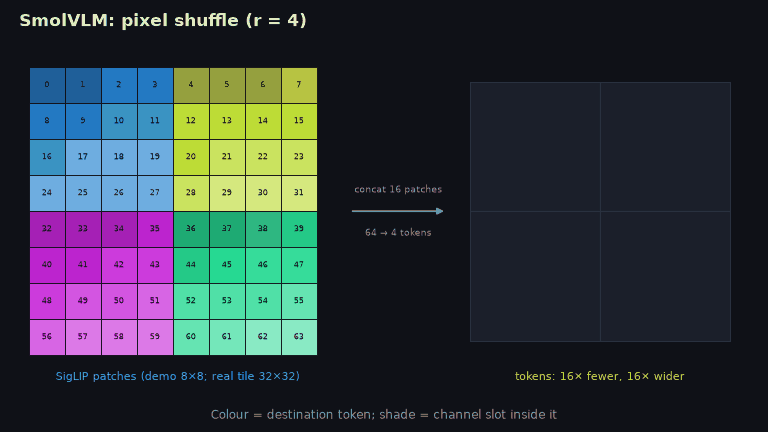

In [13]:
display(FilmCatalog.smolvlm_pixel_shuffle().show(FILMS / "smolvlm_pixel_shuffle.gif"))

✅ pixel shuffle (r = 4)                        shape (13, 16, 1024)       max|Δ| = 0.00e+00
✅ connector = shuffle + Linear                 shape (13, 16, 96)         max|Δ| = 0.00e+00


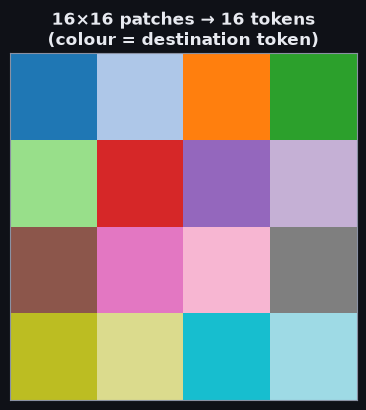

token 0 is built from patches [0, 1, 2, 3, 16, 17, 18, 19, 32, 33, 34, 35, 48, 49, 50, 51]


In [14]:
def pixel_shuffle(x, r):
    # (N, h·w, C) -> (N, (h/r)·(w/r), r²·C): concat each r×r block, channel order (row-in-block, col-in-block, C).
    N, L, C = x.shape
    h = w = int(L ** 0.5)
    x = x.view(N, h // r, r, w // r, r, C)                    # (N, block_row, in_row, block_col, in_col, C)
    return x.permute(0, 1, 3, 2, 4, 5).reshape(N, (h // r) * (w // r), r * r * C)

with torch.no_grad():
    check("pixel shuffle (r = 4)", pixel_shuffle(ours_enc, R), CONN.pixel_shuffle(ours_enc, R))
    image_tokens = pixel_shuffle(ours_enc, R) @ CONN.modality_projection.proj.weight.T
    check("connector = shuffle + Linear", image_tokens, CONN(ours_enc))

groups = MergeMappingProbe.smolvlm_pixel_shuffle(TILE // PATCH, R)
owner = np.empty((TILE // PATCH) ** 2, dtype=int)
for k, g in enumerate(groups): owner[g] = k
plt.figure(figsize=(4.4, 4.2)); plt.imshow(owner.reshape(TILE // PATCH, -1), cmap="tab20")
plt.title(f"16×16 patches → {len(groups)} tokens\n(colour = destination token)"); plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()
print(f"token 0 is built from patches {groups[0]}")

## Step 6: merging image tokens into the prompt

`inputs_merger` fills the `<image>` slots **in order**: the first 16 slots (64 in the real model) take
tile 0's tokens, the next 16 take tile 1's, …, and the last run takes the global view. Every run must be
a multiple of `image_seq_len`; the model checks this. There is no M-RoPE and no DeepStack: from here on,
the image tokens are ordinary positions in a 1-D sequence.

In [15]:
with torch.no_grad():
    embeds = LM.get_input_embeddings()(input_ids)
    ours_merged = embeds.clone()
    ours_merged[image_mask] = image_tokens.reshape(-1, image_tokens.shape[-1])      # tile-major order
    ref_merged = model.inputs_merger(input_ids=input_ids, inputs_embeds=embeds, image_hidden_states=image_tokens)
check("inputs_merger", ours_merged, ref_merged)

✅ inputs_merger                                shape (1, 245, 96)         max|Δ| = 0.00e+00


## Step 7: the SmolLM2 decoder (Llama architecture), end to end

SmolLM2 is a Llama-style decoder: RMSNorm pre-norm, **1-D RoPE**, grouped-query attention, a SwiGLU MLP,
and no biases. SmolVLM extends its context (to 16k tokens for the 256M/500M models; the paper raises the
RoPE base to do so), because a few tiles at 64 tokens each, plus text, quickly reach thousands of tokens.

Below, the **whole backbone runs from scratch**: tiles → SigLIP → pixel shuffle → projection → merge →
Llama decoder. The result is compared with `SmolVLMModel.forward`.

In [16]:
def rotate_half(x):
    x1, x2 = x[..., : x.shape[-1] // 2], x[..., x.shape[-1] // 2:]
    return torch.cat((-x2, x1), dim=-1)

def rms_norm(x, weight, eps):
    return weight * (x.float() * torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + eps)).to(x.dtype)

def llama_layer(layer, x, cos, sin):
    B, L, D = x.shape
    H, KV = tcfg.num_attention_heads, tcfg.num_key_value_heads
    d = D // H
    a, eps = layer.self_attn, tcfg.rms_norm_eps
    h = rms_norm(x, layer.input_layernorm.weight, eps)
    q = a.q_proj(h).view(B, L, H, d).transpose(1, 2)
    k = a.k_proj(h).view(B, L, KV, d).transpose(1, 2)
    v = a.v_proj(h).view(B, L, KV, d).transpose(1, 2)
    q, k = q * cos + rotate_half(q) * sin, k * cos + rotate_half(k) * sin           # 1-D RoPE
    k, v = k.repeat_interleave(H // KV, 1), v.repeat_interleave(H // KV, 1)         # GQA
    scores = q @ k.transpose(-1, -2) / math.sqrt(d)
    scores = scores.masked_fill(torch.ones(L, L, dtype=torch.bool).triu(1), float("-inf"))
    attn = scores.softmax(-1)
    x = x + a.o_proj((attn @ v).transpose(1, 2).reshape(B, L, D))
    h = rms_norm(x, layer.post_attention_layernorm.weight, eps)
    m = layer.mlp
    return x + m.down_proj(F.silu(m.gate_proj(h)) * m.up_proj(h)), attn

def smolvlm_backbone(input_ids, pixel_values):
    patch_mask = torch.ones(pixel_values.shape[0], TILE // PATCH, TILE // PATCH, dtype=torch.bool)
    tokens = pixel_shuffle(vision_encoder(pixel_values, patch_mask), R) @ CONN.modality_projection.proj.weight.T
    x = LM.get_input_embeddings()(input_ids).clone()
    x[input_ids == cfg.image_token_id] = tokens.reshape(-1, tokens.shape[-1])
    L, d = input_ids.shape[1], tcfg.hidden_size // tcfg.num_attention_heads
    inv_freq = 1.0 / tcfg.rope_parameters["rope_theta"] ** (torch.arange(0, d, 2).float() / d)
    angles = torch.arange(L).float()[:, None] * inv_freq
    cos, sin = torch.cat([angles, angles], -1).cos(), torch.cat([angles, angles], -1).sin()
    maps = []
    for layer in LM.layers:
        x, attn = llama_layer(layer, x, cos, sin)
        maps.append(attn)
    return rms_norm(x, LM.norm.weight, tcfg.rms_norm_eps), maps

with torch.no_grad():
    ours_out, attn_maps = smolvlm_backbone(input_ids, pixel_values)
    ref_out = model(input_ids=input_ids, pixel_values=pixel_values[None]).last_hidden_state
check("FULL BACKBONE: last hidden state", ours_out, ref_out, atol=2e-5)

✅ FULL BACKBONE: last hidden state             shape (1, 245, 96)         max|Δ| = 2.62e-06


### Where does the last text token look?

The last query's attention is summed over each tile's 16 image tokens. With random toy weights the
pattern means nothing semantically. The point is the **bookkeeping**: every tile is a contiguous span, so
"how much did the model use tile (r, c)?" is a sum over a slice. On a trained checkpoint (optional cell
below), the same plot shows which regions the answer depended on.

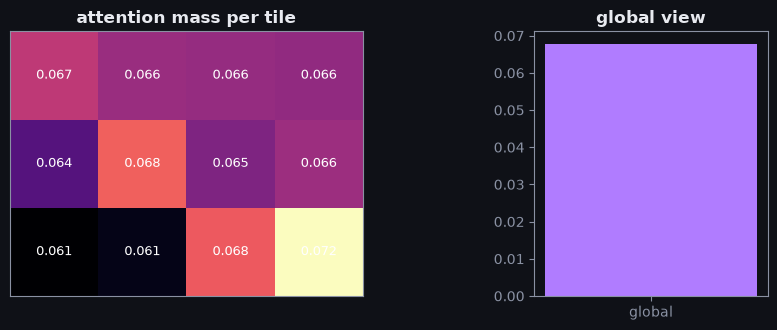

In [17]:
last = attn_maps[-1][0, :, -1].mean(0)                                   # (L,) head-mean, final query
positions = torch.nonzero(image_mask[0]).flatten()
per_image = last[positions].view(pixel_values.shape[0], -1).sum(-1)
grid_mass = per_image[:-1].view(rows, cols).numpy()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), gridspec_kw={"width_ratios": [cols, 1.2]})
axes[0].imshow(grid_mass, cmap="magma"); axes[0].set_title("attention mass per tile")
for (i, j), v in np.ndenumerate(grid_mass):
    axes[0].text(j, i, f"{v:.3f}", ha="center", va="center", color="white", fontsize=9)
axes[1].bar(["global"], [per_image[-1].item()], color="#b07cff"); axes[1].set_title("global view")
for ax in axes[:1]: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## Step 8: the token budget, SmolVLM vs Qwen3-VL

The two designs answer the same question ("how many LLM tokens does this image cost?") very differently:

* **SmolVLM-256M:** $(\text{rows}\cdot\text{cols} + 1) \times 64$. The processor first rescales the longest
  edge **to** `size.longest_edge` = 2048 px, upscaling small images as well. With default settings the
  tile grid therefore depends only on the **aspect ratio**, not the resolution: a square is always 4×4 + 1 =
  17 tiles (1088 tokens), and 16:9 is 3×4 + 1 = 13 tiles (832 tokens). To make small images cheaper, pass a
  smaller `size={"longest_edge": …}` to the processor.
* **Qwen3-VL:** $\frac{H'W'}{32^2}$ after `smart_resize`. It grows smoothly with the pixel area, clamped
  by `min_pixels` / `max_pixels` (the plot uses 64 to 1280 tokens).

The flat green lines are not a plotting bug; they are what the default SmolVLM processor does.

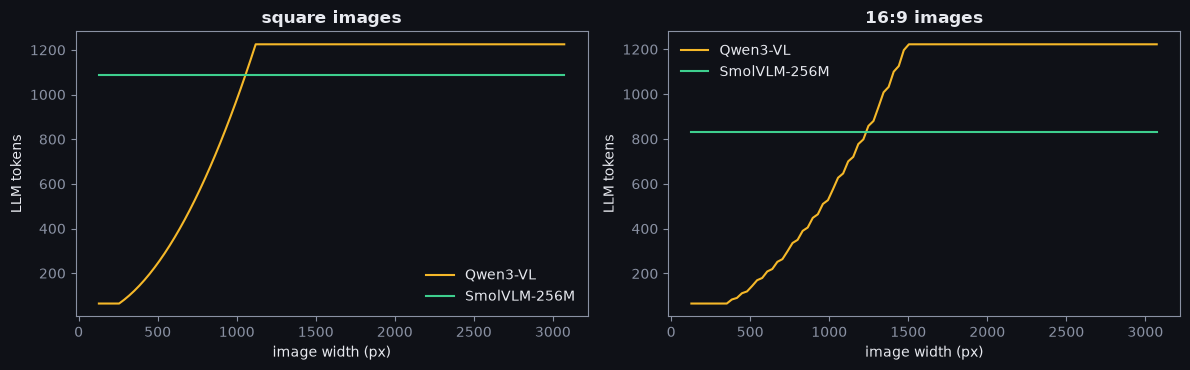

In [18]:
def qwen_tokens(h, w, factor=32, min_pixels=64 * 32 * 32, max_pixels=1280 * 32 * 32):
    h_bar, w_bar = round(h / factor) * factor, round(w / factor) * factor
    if h_bar * w_bar > max_pixels:
        beta = math.sqrt(h * w / max_pixels)
        h_bar, w_bar = max(factor, math.floor(h / beta / factor) * factor), max(factor, math.floor(w / beta / factor) * factor)
    elif h_bar * w_bar < min_pixels:
        beta = math.sqrt(min_pixels / (h * w))
        h_bar, w_bar = math.ceil(h * beta / factor) * factor, math.ceil(w * beta / factor) * factor
    return h_bar * w_bar // factor ** 2

def smol_tokens(h, w, tile=512, longest=2048, per_tile=64):
    _, _, rows_, cols_ = plan_tiles(h, w, longest, tile)
    return (rows_ * cols_ + 1) * per_tile

sides = np.arange(128, 3073, 32)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, aspect, title in [(axes[0], 1.0, "square images"), (axes[1], 16 / 9, "16:9 images")]:
    ax.plot(sides, [qwen_tokens(int(s / aspect), s) for s in sides], color="#f5b829", label="Qwen3-VL")
    ax.plot(sides, [smol_tokens(int(s / aspect), s) for s in sides], color="#3ecf8e", label="SmolVLM-256M")
    ax.set_xlabel("image width (px)"); ax.set_ylabel("LLM tokens"); ax.set_title(title); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## Summary: SmolVLM vs Qwen3-VL backbones

| | **SmolVLM** | **Qwen3-VL** |
|---|---|---|
| resolution strategy | fixed square tiles + global view | native dynamic resolution (`smart_resize`) |
| vision encoder | SigLIP base (93M) / so400m, learned abs. positions, NaViT buckets | SigLIP-2 so400m + interpolated table **and** 2-D RoPE |
| batching | one encoder pass per tile (padded tiles masked) | all patches packed, `cu_seqlens` segments |
| compression | pixel shuffle r = 4 (16×) + one Linear | 2×2 merge (4×) + LN + 2-layer MLP |
| LLM tokens per 512×512 px region | 64 (one tile) | 256 |
| what sets the token count | aspect ratio (default processor) | pixel area |
| 2-D layout for the LLM | `<row_r_col_c>` / `<global-img>` special tokens | interleaved M-RoPE (t, h, w) positions |
| multi-level features | last layer only | DeepStack (3 taps added to LLM layers 0–2) |
| language model | SmolLM2 (Llama: 1-D RoPE, GQA, SwiGLU) | Qwen3 (QK-norm, GQA, SwiGLU) |
| design goal | tokens and memory on device | accuracy at any resolution, long video |

### Optional: the same checks on the real weights

Set `RUN_PRETRAINED = True` to download `HuggingFaceTB/SmolVLM-256M-Instruct` (about 0.5 GB). The cell
rebinds the globals the from-scratch functions read (`model`, `VIS`, `CONN`, `LM`, `cfg`, …) to the real
model and compares the full backbone on a real processor output.

In [19]:
RUN_PRETRAINED = False
if RUN_PRETRAINED:
    from transformers import AutoProcessor, SmolVLMForConditionalGeneration
    repo = "HuggingFaceTB/SmolVLM-256M-Instruct"
    real = SmolVLMForConditionalGeneration.from_pretrained(repo, dtype=torch.float32).eval()
    proc = AutoProcessor.from_pretrained(repo)
    model, cfg = real.model, real.config
    VIS, CONN, LM = model.vision_model, model.connector, model.text_model
    vcfg, tcfg = cfg.vision_config, cfg.text_config
    TILE, PATCH, R = vcfg.image_size, vcfg.patch_size, cfg.scale_factor
    scene = (SyntheticScene.render(1100, 1600) * 255).astype(np.uint8)
    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": "Describe the scene."}]}]
    batch = proc(text=[proc.apply_chat_template(messages, add_generation_prompt=True)], images=[[scene]],
                 return_tensors="pt")
    with torch.no_grad():
        ours_out, _ = smolvlm_backbone(batch["input_ids"], batch["pixel_values"][0])
        ref_out = model(input_ids=batch["input_ids"], pixel_values=batch["pixel_values"]).last_hidden_state
    check("REAL SmolVLM-256M backbone", ours_out, ref_out, atol=5e-3)

## References

* A. Marafioti et al. **SmolVLM: Redefining small and efficient multimodal models**, 2025. [arXiv:2504.05299](https://arxiv.org/abs/2504.05299)
* H. Laurençon et al. **Building and better understanding vision-language models** (Idefics3), 2024. [arXiv:2408.12637](https://arxiv.org/abs/2408.12637)
* X. Zhai et al. **Sigmoid loss for language image pre-training** (SigLIP), 2023. [arXiv:2303.15343](https://arxiv.org/abs/2303.15343)
* M. Dehghani et al. **Patch n' Pack: NaViT**, 2023. [arXiv:2307.06304](https://arxiv.org/abs/2307.06304)
* W. Shi et al. **Real-time single image and video super-resolution using an efficient sub-pixel CNN** (pixel shuffle), 2016. [arXiv:1609.05158](https://arxiv.org/abs/1609.05158)
* 🤗 `transformers` reference implementation: `models/smolvlm/`.